In [16]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torchaudio
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression 
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix,ConfusionMatrixDisplay, precision_score, recall_score, f1_score
from tqdm.auto import tqdm 
from config import CHILD, CHILD_AFR_SADILAR, ADULT_NCHLT, NOISY_DIR, RESULTS_DIR

tqdm.pandas()    
#Fixed seeds and the 16 kHz rate MMS expects
random.seed(42)
np.random.seed(42)
SAMPLE_RATE = 16000

In [17]:
from transformers import Wav2Vec2ForSequenceClassification, AutoFeatureExtractor

#Facebook LLM ID
lid_model_id = "facebook/mms-lid-126"

feature_extractor = AutoFeatureExtractor.from_pretrained(lid_model_id)

#wav2vec 2.0 encoder with a classification head over 126 languages
model = Wav2Vec2ForSequenceClassification.from_pretrained(lid_model_id)

device = "cpu"

#eval() switches off dropout so the embeddings are repeatable
lid_model = model.to(device).eval()
print(f"Model loaded on {device}")

Model loaded on cpu


In [18]:
#Takes n_total utterances spread as evenly as possible over the speakers
def balanced_subsample(df, n_total, group="speaker", seed=42):
    # rank utterances within each speaker (0,1,2,...) after shuffling,
    # then take the lowest ranks first -> one per speaker before a second, etc.
    shuffled = df.sample(frac=1, random_state=seed)
    rank = shuffled.groupby(group).cumcount()
    return (shuffled.assign(_r=rank.values)
                    .sort_values(["_r", group])
                    .head(n_total)
                    .drop(columns="_r")
                    .reset_index(drop=True))

In [19]:
#LOADING CHILD NORTHERN SOTHO DATASET : 
CHILD_MANIFEST_NSO, CHILD_AUDIO_DIR_NSO = CHILD["nso"]

nso_child_df = pd.read_csv(CHILD_MANIFEST_NSO)
nso_child_df["path"]       = nso_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NSO / f)
nso_child_df["duration_s"] = (nso_child_df["end_ms"] - nso_child_df["start_ms"]) / 1000.0

#Already 10 085 utterances, so no subsampling
print(f"Loaded {len(nso_child_df)} NSO audio segments")
nso_child_df["true_lang"] = "nso"

total_s = nso_child_df["duration_s"].sum()
print(f"Total duration of Sesotho sa Leboa child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 10085 NSO audio segments
Total duration of Sesotho sa Leboa child dataset: 28990.92 seconds, or 483.18 minutes, or 8.05 hours.


In [20]:
#LOADING CHILD ISIXHOSA DATASET
CHILD_MANIFEST_XHO, CHILD_AUDIO_DIR_XHO = CHILD["xho"]

xho_child_df = pd.read_csv(CHILD_MANIFEST_XHO)
xho_child_df["path"] = xho_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_XHO / f)
xho_child_df["true_lang"] = "xho"       
print(f"Loaded {len(xho_child_df)} XHO audio segments.")

#Same subsampling as for Afrikaans
xho_child_df = balanced_subsample(xho_child_df, n_total=10085, group="speaker")   
print(xho_child_df["speaker"].value_counts().describe())
print(f"Xhosa Child files subsampled: {len(xho_child_df)} / {len(xho_child_df)}")
total_s = xho_child_df["duration_s"].sum()
print(f"Total duration of Xhosa child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 12947 XHO audio segments.
count    153.000000
mean      65.915033
std       18.706510
min        3.000000
25%       53.000000
50%       79.000000
75%       80.000000
max       80.000000
Name: count, dtype: float64
Xhosa Child files subsampled: 10085 / 10085
Total duration of Xhosa child dataset: 15011.88 seconds, or 250.20 minutes, or 4.17 hours.


In [21]:
#LOADING CHILD AFR DATASET:
CHILD_MANIFEST_AFR, CHILD_AUDIO_DIR_AFR = CHILD["afr"]

afr_child_df = pd.read_csv(CHILD_MANIFEST_AFR)
afr_child_df["path"] = afr_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_AFR / f)
afr_child_df["true_lang"] = "afr"   
print(f"Loaded {len(afr_child_df)} AFR audio segments.") 

#Cut every language down to 10 085 utterances, the size of the Sesotho sa Leboa set
afr_child_df = balanced_subsample(afr_child_df, n_total=10085)  
print(afr_child_df["speaker"].value_counts().describe())
print(f"Afrikaans Child files subsampled : {len(afr_child_df)} / {len(afr_child_df)}")
afr_child_df["true_lang"] = "afr"

total_s = afr_child_df["duration_s"].sum()
print(f"Total duration of Afrikaans child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 13990 AFR audio segments.
count    154.000000
mean      65.487013
std       13.191519
min       26.000000
25%       60.000000
50%       73.000000
75%       74.000000
max       74.000000
Name: count, dtype: float64
Afrikaans Child files subsampled : 10085 / 10085
Total duration of Afrikaans child dataset: 13779.49 seconds, or 229.66 minutes, or 3.83 hours.


In [ ]:
#LOADING CHILD SADILAR AFR DATASET
#Afrikaans from the SADiLaR corpus, recorded with the same setup as Sesotho sa Leboa
CHILD_MANIFEST_AFR_SAD, CHILD_AUDIO_DIR_AFR_SAD = CHILD_AFR_SADILAR

afr_sad_child_df = pd.read_csv(CHILD_MANIFEST_AFR_SAD)
afr_sad_child_df = afr_sad_child_df[afr_sad_child_df["duration_s"] >= 0.025].reset_index(drop=True)
afr_sad_child_df["path"] = afr_sad_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_AFR_SAD / f)
afr_sad_child_df["true_lang"] = "afr"   
print(f"Loaded {len(afr_sad_child_df)} AFR audio segments.") 

print(afr_sad_child_df["speaker"].value_counts().describe())
afr_sad_child_df["true_lang"] = "afr"
total_s = afr_sad_child_df["duration_s"].sum()
print(f"Total duration of Afrikaans child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 10842 AFR audio segments.
count     27.000000
mean     401.555556
std      140.429652
min      199.000000
25%      329.000000
50%      370.000000
75%      469.000000
max      757.000000
Name: count, dtype: float64
Total duration of Afrikaans child dataset: 31461.36 seconds, or 524.36 minutes, or 8.74 hours.


In [8]:
#Mean-pooled embedding of MMS layer 9, the layer chosen on validation in 03_layer_sweep_mms
def extract_embeddings_best_layer(audio_path, model=lid_model, feature_extractor=feature_extractor, device=device):
    waveform, sr = torchaudio.load(str(audio_path))
    if sr != SAMPLE_RATE: 
        waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE) #Adapt Sample Rate
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True) #Average to mono if stereo 
    
    #prepare the input of the model by extracting features from the audio waveform
    inputs = feature_extractor(waveform.squeeze().numpy(),
        sampling_rate=SAMPLE_RATE,
        return_tensors="pt" #package as pytorch tensors
    ).to(device)

    with torch.no_grad() : #do not keep track of gradients as we are not training the model.
        outputs = model.wav2vec2(inputs["input_values"], output_hidden_states=True)
        hs = outputs.hidden_states[9]
        pooled = hs.mean(dim=1)

    return pooled.squeeze().cpu().numpy() 

In [23]:
#Only needed to rebuild the embeddings from the audio, the next cell loads the saved ones
#REGENERATE EMBEDDINGS AND SAVE :
#AFR (Babaloon)
afr_child_df["embeddings"] = afr_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
afr_child_df.to_pickle("EMBEDDINGS/afr_child_df_best_layer.pkl")

#AFR (SADiLaR)
afr_sad_child_df["embeddings"] = afr_sad_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
afr_sad_child_df.to_pickle("EMBEDDINGS/afr_sadilar_dataframe_best_layer.pkl")

#XHO
xho_child_df["embeddings"] = xho_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
xho_child_df.to_pickle("EMBEDDINGS/xho_child_df_best_layer.pkl")

#NSO
nso_child_df["embeddings"] = nso_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nso_child_df.to_pickle("EMBEDDINGS/nso_child_df_best_layer.pkl")

  0%|          | 0/10085 [00:00<?, ?it/s]

/Users/conarj/Library/Python/3.9/lib/python/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


KeyboardInterrupt: 

In [24]:
afr_child_df = pd.read_pickle("EMBEDDINGS/afr_child_df_best_layer.pkl")
nso_child_df = pd.read_pickle("EMBEDDINGS/nso_child_df_best_layer.pkl")
xho_child_df = pd.read_pickle("EMBEDDINGS/xho_child_df_best_layer.pkl")
afr_sad_child_df = pd.read_pickle("EMBEDDINGS/afr_sadilar_dataframe_best_layer.pkl")

In [25]:
#Drop SADiLaR segments shorter than 25 ms, which are too short for the model
print("Number of AFR segments before removal: ", len(afr_sad_child_df))
count = 0
for dur in afr_sad_child_df["duration_s"].values: 
    if dur < 0.025: 
        count += 1
        path = afr_sad_child_df[afr_sad_child_df["duration_s"] == dur]["path"].values[0]
        #Remove the segment from the dataframe
        afr_sad_child_df = afr_sad_child_df[afr_sad_child_df["duration_s"] != dur]
print(f"Number of AFR segments shorter than 25ms: {count}")
print("Number of AFR segments after removal: ", len(afr_sad_child_df))

Number of AFR segments before removal:  10841
Number of AFR segments shorter than 25ms: 0
Number of AFR segments after removal:  10841


In [26]:
#SADILAR TRAINING SPLIT : 

#Afrikaans vs Sesotho sa Leboa, both from SADiLaR, split by speaker
train_dfs = [] 
test_dfs = [] 
val_dfs = [] 

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
afr_split = next(gss1.split(afr_sad_child_df, groups=afr_sad_child_df["speaker"])) #next means grab indices
afr_sad_train_df = afr_sad_child_df.iloc[afr_split[0]].reset_index(drop=True)
afr_temp_test = afr_sad_child_df.iloc[afr_split[1]].reset_index(drop=True)

print("Afrikaans training length: ", len(afr_sad_train_df))

#Split the test set into validation and test set
afr_val_split = next(gss2.split(afr_sad_child_df.iloc[afr_split[1]], groups=afr_sad_child_df.iloc[afr_split[1]]["speaker"]))
afr_sad_val_df = afr_temp_test.iloc[afr_val_split[0]].reset_index(drop=True)
afr_sad_test_df = afr_temp_test.iloc[afr_val_split[1]].reset_index(drop=True)

#Check if any speakers are in both train and test set
for speaker in afr_sad_test_df["speaker"].unique(): 
    if speaker in afr_sad_train_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both train and test set for Afrikaans!")

#Check if any speakers are in both train and val set
for speaker in afr_sad_val_df["speaker"].unique():
    if speaker in afr_sad_train_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both train and val set for Afrikaans!")

#Check if any speakers are in both test and val set
for speaker in afr_sad_test_df["speaker"].unique():
    if speaker in afr_sad_val_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both test and val set for Afrikaans!")


train_dfs.append(afr_sad_train_df)
test_dfs.append(afr_sad_test_df)
val_dfs.append(afr_sad_val_df)

nso_split = next(gss1.split(nso_child_df, groups=nso_child_df["speaker"])) #next means grab indices
nso_train_df = nso_child_df.iloc[nso_split[0]].reset_index(drop=True)
nso_temp_test = nso_child_df.iloc[nso_split[1]].reset_index(drop=True)

print("Northern Sotho training length: ", len(nso_train_df))

#Split the test set into validation and test set
nso_val_split = next(gss2.split(nso_child_df.iloc[nso_split[1]], groups=nso_child_df.iloc[nso_split[1]]["speaker"]))
nso_val_df = nso_temp_test.iloc[nso_val_split[0]].reset_index(drop=True)
nso_test_df = nso_temp_test.iloc[nso_val_split[1]].reset_index(drop=True)

#Check if any speakers are in both train and test set
for speaker in nso_test_df["speaker"].unique(): 
    if speaker in nso_train_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both train and test set for Afrikaans!")

#Check if any speakers are in both train and val set
for speaker in nso_val_df["speaker"].unique():
    if speaker in nso_train_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both train and val set for Afrikaans!")

#Check if any speakers are in both test and val set
for speaker in nso_test_df["speaker"].unique():
    if speaker in nso_val_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both test and val set for Afrikaans!")


train_dfs.append(nso_train_df)
test_dfs.append(nso_test_df)
val_dfs.append(nso_val_df)

train_df = pd.concat(train_dfs, ignore_index=True)
test_df = pd.concat(test_dfs, ignore_index=True)
val_df = pd.concat(val_dfs, ignore_index=True)

#Check that no speaker is in more than one set (English uses the session as speaker)
def speaker_ids(df):
    spk = df["session"].where(df["true_lang"] == "eng", df["speaker"])
    return set(zip(df["true_lang"], spk))

train_spk, val_spk, test_spk = speaker_ids(train_df), speaker_ids(val_df), speaker_ids(test_df)
assert not train_spk & val_spk,  "speaker in train and val"
assert not train_spk & test_spk, "speaker in train and test"
assert not val_spk & test_spk,   "speaker in val and test"

#Same supports as in the report
assert test_df["true_lang"].value_counts().to_dict() == {"nso": 1148, "afr": 1011}
assert val_df["true_lang"].value_counts().to_dict()  == {"nso": 974,  "afr": 965}

Afrikaans training length:  8865
Northern Sotho training length:  7963


In [27]:
#Binary classifier on the SADiLaR pair, chance is 50%
cf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
train_embeddings = np.vstack(train_df["embeddings"].values)
train_labels = train_df["true_lang"].values 

cf.fit(train_embeddings, train_labels) 
y_pred = cf.predict(np.vstack(test_df["embeddings"].values))
print(classification_report(test_df["true_lang"].values, y_pred))

              precision    recall  f1-score   support

         afr       0.97      0.84      0.90      1011
         nso       0.88      0.98      0.93      1148

    accuracy                           0.92      2159
   macro avg       0.93      0.91      0.91      2159
weighted avg       0.92      0.92      0.92      2159



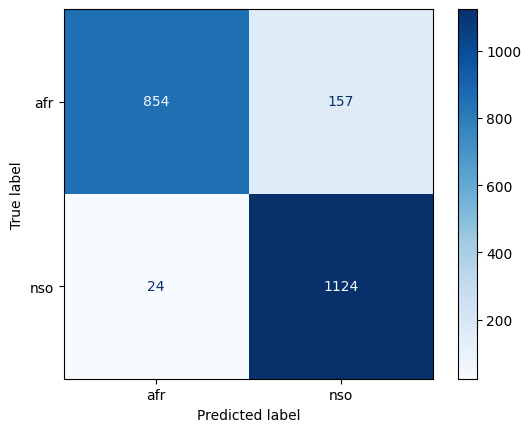

In [28]:
#Visualise the confusion matrix
#Rows are the true languages, columns the predicted ones
cm = confusion_matrix(test_df["true_lang"].values, y_pred, labels=cf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cf.classes_)
disp.plot(cmap=plt.cm.Blues)


In [29]:
#BABALOON TRAINING SPLIT: 
#Afrikaans vs isiXhosa, both from the Babaloon study, split by speaker
train_dfs = [] 
test_dfs = [] 
val_dfs = [] 

#Afrikaans :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
afr_split = next(gss1.split(afr_child_df, groups=afr_child_df["speaker"])) #next means grab indices 
afr_bab_train_df = afr_child_df.iloc[afr_split[0]].reset_index(drop=True)
afr_temp_test = afr_child_df.iloc[afr_split[1]].reset_index(drop=True)

print("Afrikaans training length: ", len(afr_bab_train_df))

#Split the test set into validation and test set
afr_val_split = next(gss2.split(afr_child_df.iloc[afr_split[1]], groups=afr_child_df.iloc[afr_split[1]]["speaker"]))
afr_bab_val_df = afr_temp_test.iloc[afr_val_split[0]].reset_index(drop=True)
afr_bab_test_df = afr_temp_test.iloc[afr_val_split[1]].reset_index(drop=True)

#Check if any speakers are in both train and test set
for speaker in afr_bab_test_df["speaker"].unique(): 
    if speaker in afr_bab_train_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both train and test set for Afrikaans!")

#Check if any speakers are in both train and val set
for speaker in afr_bab_val_df["speaker"].unique():
    if speaker in afr_bab_train_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both train and val set for Afrikaans!")

#Check if any speakers are in both test and val set
for speaker in afr_bab_test_df["speaker"].unique():
    if speaker in afr_bab_val_df["speaker"].unique(): 
        print(f"Speaker {speaker} is in both test and val set for Afrikaans!")

train_dfs.append(afr_bab_train_df)
test_dfs.append(afr_bab_test_df)
val_dfs.append(afr_bab_val_df)

#Xhosa : 
xho_split = next(gss1.split(xho_child_df,groups=xho_child_df["speaker"]))
xho_bab_train_df = xho_child_df.iloc[xho_split[0]].reset_index(drop=True)
xho_temp_test = xho_child_df.iloc[xho_split[1]].reset_index(drop=True)

print("Xhosa training length: ", len(xho_bab_train_df))

#Split test into val and test
xho_val_split = next(gss2.split(xho_child_df.iloc[xho_split[1]], groups=xho_child_df.iloc[xho_split[1]]["speaker"]))
xho_bab_val_df = xho_temp_test.iloc[xho_val_split[0]].reset_index(drop=True)
xho_bab_test_df = xho_temp_test.iloc[xho_val_split[1]].reset_index(drop=True)

#Check if any speakers are in both train and test set
for speaker in xho_bab_test_df["speaker"].unique():
    if speaker in xho_bab_train_df["speaker"].unique():
        print(f"Speaker {speaker} is in both train and test set for Xhosa!")

#Check if any speakers are in both train and val set
for speaker in xho_bab_val_df["speaker"].unique():
    if speaker in xho_bab_train_df["speaker"].unique():
        print(f"Speaker {speaker} is in both train and val set for Xhosa!")

#Check if any speakers are in both test and val set
for speaker in xho_bab_test_df["speaker"].unique():
    if speaker in xho_bab_val_df["speaker"].unique():
        print(f"Speaker {speaker} is in both test and val set for Xhosa!")

train_dfs.append(xho_bab_train_df)
test_dfs.append(xho_bab_test_df)
val_dfs.append(xho_bab_val_df)

train_df = pd.concat(train_dfs, ignore_index=True)
test_df = pd.concat(test_dfs, ignore_index=True)
val_df = pd.concat(val_dfs, ignore_index=True)

print("Train length: ", len(train_df))
print("Test length: ", len(test_df))
print("Val length: ", len(val_df))

train_spk, val_spk, test_spk = speaker_ids(train_df), speaker_ids(val_df), speaker_ids(test_df)
assert not train_spk & val_spk,  "speaker in train and val"
assert not train_spk & test_spk, "speaker in train and test"
assert not val_spk & test_spk,   "speaker in val and test"

#Same supports as in the report
assert test_df["true_lang"].value_counts().to_dict() == {"afr": 1076, "xho": 1046}
assert val_df["true_lang"].value_counts().to_dict()  == {"xho": 1040, "afr": 955}

Afrikaans training length:  8054
Xhosa training length:  7999
Train length:  16053
Test length:  2122
Val length:  1995


In [30]:
#Binary classifier on the Babaloon pair, chance is 50%
cf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
train_embeddings = np.vstack(train_df["embeddings"].values)
train_labels = train_df["true_lang"].values 

cf.fit(train_embeddings, train_labels) 
y_pred = cf.predict(np.vstack(test_df["embeddings"].values))
print(classification_report(test_df["true_lang"].values, y_pred))

              precision    recall  f1-score   support

         afr       0.93      0.86      0.89      1076
         xho       0.87      0.94      0.90      1046

    accuracy                           0.90      2122
   macro avg       0.90      0.90      0.90      2122
weighted avg       0.90      0.90      0.90      2122



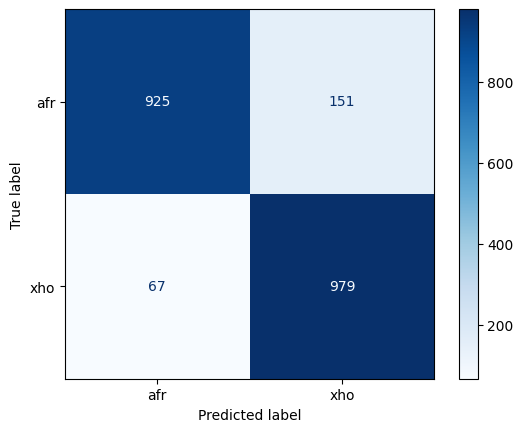

In [31]:
#Visualise the confusion matrix
#Rows are the true languages, columns the predicted ones
cm = confusion_matrix(test_df["true_lang"].values, y_pred, labels=cf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cf.classes_)
disp.plot(cmap=plt.cm.Blues)